In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import rasterio
import joblib
import time
from rasterio.warp import reproject, Resampling, calculate_default_transform
from rasterio.windows import Window, transform as window_transform
import matplotlib.pyplot as plt

os.makedirs("outputs", exist_ok=True)
print("Imports OK")

Imports OK


echarge les 4 artefacts sauvegardés (Stacking, scaler, liste des features, distributions de rangs) et prépare le mapping vers les fichiers `.tif` d'origine pour la phase de cartographie.

In [2]:
MODEL_DIR = "data/processed"

stacking      = joblib.load(os.path.join(MODEL_DIR, "stacking_model_improvedV2.pkl"))
scaler        = joblib.load(os.path.join(MODEL_DIR, "scaler_improvedV2.pkl"))
feature_names = joblib.load(os.path.join(MODEL_DIR, "feature_names_improvedV2.pkl"))
rank_dists    = joblib.load(os.path.join(MODEL_DIR, "rank_distributions.pkl"))

ORIGINAL_FEATURES = ["DEM", "Slope", "Aspect", "Curvature", "TWI",
                     "NDVI", "NDBI", "DD", "DR", "GFI"]
FEATURE_TO_TIF = {f: f"{f}.tif" for f in ORIGINAL_FEATURES}

print(f"Features du modèle ({len(feature_names)}) :")
print(f"  {feature_names}\n")
print("Modèle V2 et distributions chargés")

Features du modèle (15) :
  ['DEM', 'Slope', 'Aspect', 'Curvature', 'TWI', 'NDVI', 'NDBI', 'DD', 'DR', 'GFI', 'DEM_Slope', 'TWI_DD', 'NDVI_NDBI', 'Vulnerability', 'Roughness']

Modèle V2 et distributions chargés


Crée le DEM 100 m (grille de travail) et ouvre les 10 rasters de facteurs pour la cartographie.

In [3]:
DEM_100M = "data/raw/DEM_100m.tif"
if not os.path.exists(DEM_100M):
    print("⏳ Création de DEM_100m.tif...")
    with rasterio.open("data/raw/DEM.tif") as src:
        t100, w100, h100 = calculate_default_transform(
            src.crs, src.crs, src.width, src.height, *src.bounds, resolution=100
        )
        prof = src.profile.copy()
        prof.update(transform=t100, width=w100, height=h100, res=(100, 100), compress="lzw")
        arr = np.zeros((h100, w100), dtype=np.float32)
        reproject(rasterio.band(src, 1), arr, dst_transform=t100, dst_crs=src.crs,
                  resampling=Resampling.bilinear)
        with rasterio.open(DEM_100M, "w", **prof) as dst:
            dst.write(arr, 1)
    print(" DEM_100m.tif créé")

REF_PATH = DEM_100M
with rasterio.open(REF_PATH) as ref:
    ref_crs       = ref.crs
    ref_transform = ref.transform
    ref_shape     = ref.shape
    ref_res       = ref.res

print(f"\nGrille de référence (DEM 100m) :")
print(f"  Dimensions : {ref_shape[1]:,} × {ref_shape[0]:,} pixels")
print(f"  Total      : {ref_shape[0] * ref_shape[1]:,} pixels")
print(f"  CRS        : {ref_crs}")

srcs = {name: rasterio.open(f"data/raw/{FEATURE_TO_TIF[name]}") for name in ORIGINAL_FEATURES}
print(f"\n {len(srcs)} rasters ouverts")


Grille de référence (DEM 100m) :
  Dimensions : 1,406 × 1,614 pixels
  Total      : 2,269,284 pixels
  CRS        : EPSG:32645

 10 rasters ouverts


Définit les 3 fonctions clés de la cartographie : lecture d'un facteur aligné sur la grille de référence (avec fast-path), calcul de percentile via distribution figée, et reproduction exacte du feature engineering.

In [4]:
def read_factor_aligned(src, ref_window, ref_transform, ref_crs, ref_shape):
    """Lit un facteur aligné sur la grille de référence."""
    h, w = int(ref_window.height), int(ref_window.width)
    if (src.crs == ref_crs and src.transform == ref_transform
        and (src.height, src.width) == ref_shape):
        return src.read(1, window=ref_window).astype(np.float32)

    dest = np.full((h, w), np.nan, dtype=np.float32)
    win_t = window_transform(ref_window, ref_transform)
    reproject(
        rasterio.band(src, 1), dest,
        dst_transform=win_t, dst_crs=ref_crs,
        resampling=Resampling.bilinear,
        src_nodata=src.nodata, dst_nodata=np.nan,
    )
    return dest


def get_percentile_from_sorted(values, sorted_ref):
    """Convertit des valeurs en percentile via distribution de référence."""
    n = len(sorted_ref)
    idx = np.searchsorted(sorted_ref, values, side="right")
    return idx / n


def build_features_block(feats_dict, rank_dists):
    """Applique le feature engineering identique au training."""
    DEM, Slope = feats_dict["DEM"], feats_dict["Slope"]
    TWI, DD    = feats_dict["TWI"], feats_dict["DD"]
    NDVI, NDBI = feats_dict["NDVI"], feats_dict["NDBI"]

    dem_slope = DEM / (Slope + 1)
    twi_dd    = TWI * DD
    ndvi_ndbi = NDVI - NDBI

    vuln = (
        -get_percentile_from_sorted(DEM,  rank_dists["DEM"])
        + get_percentile_from_sorted(TWI,  rank_dists["TWI"])
        + get_percentile_from_sorted(DD,   rank_dists["DD"])
        - get_percentile_from_sorted(NDVI, rank_dists["NDVI"])
    )

    out = dict(feats_dict)
    out["DEM_Slope"]     = dem_slope
    out["TWI_DD"]        = twi_dd
    out["NDVI_NDBI"]     = ndvi_ndbi
    out["Vulnerability"] = vuln
    out["Roughness"]     = np.zeros_like(dem_slope)
    return out


print("Fonctions définies")

Fonctions définies


pplique le modèle Stacking à toute la grille en traitant l'image par blocs de 512×512 (gestion mémoire), calcule les probabilités pixel par pixel et affiche la progression.

In [5]:
BLOCK_SIZE = 512
prob_map   = np.full(ref_shape, np.nan, dtype=np.float32)

n_by = (ref_shape[0] + BLOCK_SIZE - 1) // BLOCK_SIZE
n_bx = (ref_shape[1] + BLOCK_SIZE - 1) // BLOCK_SIZE
total = n_by * n_bx
print(f"Traitement de {total} blocs de {BLOCK_SIZE}×{BLOCK_SIZE}...\n")

t0 = time.time()
processed   = 0
valid_total = 0

for by in range(n_by):
    for bx in range(n_bx):
        y0, x0 = by * BLOCK_SIZE, bx * BLOCK_SIZE
        h = min(BLOCK_SIZE, ref_shape[0] - y0)
        w = min(BLOCK_SIZE, ref_shape[1] - x0)
        win = Window(x0, y0, w, h)

        feats = {}
        valid = np.ones((h, w), dtype=bool)
        for name in ORIGINAL_FEATURES:
            f = read_factor_aligned(srcs[name], win, ref_transform, ref_crs, ref_shape)
            feats[name] = f
            valid &= np.isfinite(f)

        if valid.sum() > 0:
            feats_valid = {k: v[valid] for k, v in feats.items()}
            feats_fe    = build_features_block(feats_valid, rank_dists)

            X_block  = np.stack([feats_fe[f] for f in feature_names], axis=1)
            X_scaled = scaler.transform(X_block)
            probs    = stacking.predict_proba(X_scaled)[:, 1]

            block_out = np.full((h, w), np.nan, dtype=np.float32)
            block_out[valid] = probs
            prob_map[y0:y0+h, x0:x0+w] = block_out
            valid_total += int(valid.sum())

        processed += 1
        if processed % 5 == 0 or processed == total:
            elapsed = time.time() - t0
            pct = 100 * processed / total
            eta = (elapsed / processed) * (total - processed)
            print(f"  Bloc {processed:>4}/{total}  ({pct:5.1f}%)  "
                  f"pixels valides : {valid_total:,}  "
                  f"ETA : {eta/60:.1f} min")

print(f"\n Carte calculée : {valid_total:,} pixels valides")
print(f"Temps total : {(time.time()-t0)/60:.1f} min")

Traitement de 12 blocs de 512×512...

  Bloc    5/12  ( 41.7%)  pixels valides : 633,762  ETA : 11.9 min
  Bloc   10/12  ( 83.3%)  pixels valides : 1,195,071  ETA : 3.2 min
  Bloc   12/12  (100.0%)  pixels valides : 1,205,173  ETA : 0.0 min

 Carte calculée : 1,205,173 pixels valides
Temps total : 16.1 min


Exporte la grille `prob_map` en GeoTIFF float32 compressé  

In [6]:
PROB_TIF = "outputs/flood_susceptibility_prob_kosi_v5.tif"

with rasterio.open(
    PROB_TIF, "w", driver="GTiff",
    height=ref_shape[0], width=ref_shape[1],
    count=1, dtype="float32",
    crs=ref_crs, transform=ref_transform,
    nodata=np.nan, compress="lzw",
) as dst:
    dst.write(prob_map, 1)

print(f" Sauvegardé : {PROB_TIF}")
print(f"   Taille : {os.path.getsize(PROB_TIF)/1e6:.1f} MB")

 Sauvegardé : outputs/flood_susceptibility_prob_kosi_v5.tif
   Taille : 5.7 MB


Convertit la carte continue de probabilités en 4 classes de risque discrètes (Très faible / Faible / Élevé / Très élevé) via le seuil de décision 0.70, et exporte le résultat en GeoTIFF uint8 avec statistiques de répartition.


In [ ]:
SEUIL_OPT = 0.70   

class_map = np.zeros(ref_shape, dtype=np.uint8)
valid_mask = np.isfinite(prob_map)

class_map[valid_mask & (prob_map <  0.40)]                        = 1
class_map[valid_mask & (prob_map >= 0.40) & (prob_map < SEUIL_OPT)] = 2
class_map[valid_mask & (prob_map >= SEUIL_OPT) & (prob_map < 0.90)] = 3
class_map[valid_mask & (prob_map >= 0.90)]                        = 4

CLASS_TIF = "outputs/flood_susceptibility_class_kosi_v5.tif"
with rasterio.open(
    CLASS_TIF, "w", driver="GTiff",
    height=ref_shape[0], width=ref_shape[1],
    count=1, dtype="uint8",
    crs=ref_crs, transform=ref_transform,
    nodata=0, compress="lzw",
) as dst:
    dst.write(class_map, 1)

print(f" Sauvegardé : {CLASS_TIF}")
print(f"   Taille : {os.path.getsize(CLASS_TIF)/1e6:.1f} MB")

# Distribution des classes
for cls, lbl in {1: "Très faible", 2: "Faible", 3: "Élevé", 4: "Très élevé"}.items():
    n = int((class_map == cls).sum())
    pct = 100 * n / valid_mask.sum() if valid_mask.sum() else 0
    print(f"  Classe {cls} ({lbl:12s}) : {n:>10,} pixels ({pct:5.1f}%)")

 Sauvegardé : outputs/flood_susceptibility_class_kosi_v5.tif
   Taille : 0.1 MB
  Classe 1 (Très faible ) :  1,030,580 pixels ( 85.5%)
  Classe 2 (Faible      ) :     31,401 pixels (  2.6%)
  Classe 3 (Élevé       ) :     37,316 pixels (  3.1%)
  Classe 4 (Très élevé  ) :    105,876 pixels (  8.8%)


Convertit les pixels de chaque classe en surface (km²) et en pourcentage, puis affiche un tableau et un bar chart comparant les 4 niveaux de risque sur l'ensemble du Kosi Megafan.

STATISTIQUES DE RISQUE — KOSI MEGAFAN (Modèle V2)
 Classe      Niveau  Pixels  Surface (km²)  % zone valide
      1 Très faible 1030580        10305.8          85.51
      2      Faible   31401          314.0           2.61
      3       Élevé   37316          373.2           3.10
      4  Très élevé  105876         1058.8           8.79

Surface totale analysée : 12,051.8 km²


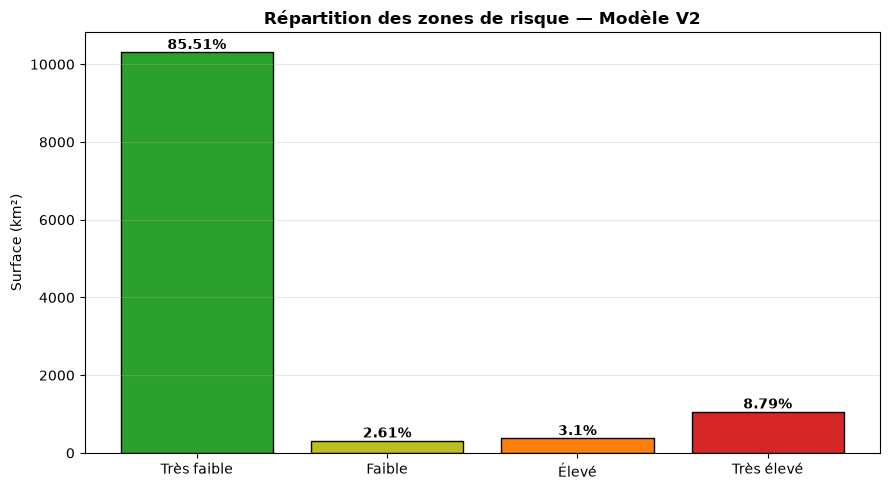

In [8]:
pixel_km2 = (ref_res[0] * ref_res[1]) / 1e6

rows = []
for cls, lbl in {1: "Très faible", 2: "Faible", 3: "Élevé", 4: "Très élevé"}.items():
    n = int((class_map == cls).sum())
    rows.append({
        "Classe": cls, "Niveau": lbl, "Pixels": n,
        "Surface (km²)": round(n * pixel_km2, 1),
        "% zone valide": round(100 * n / valid_mask.sum(), 2),
    })

stats_df = pd.DataFrame(rows)
print("=" * 70)
print("STATISTIQUES DE RISQUE — KOSI MEGAFAN (Modèle V2)")
print("=" * 70)
print(stats_df.to_string(index=False))
print(f"\nSurface totale analysée : {stats_df['Surface (km²)'].sum():,.1f} km²")

# Graphique
colors = {1: "#2ca02c", 2: "#bcbd22", 3: "#ff7f0e", 4: "#d62728"}
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(stats_df["Niveau"], stats_df["Surface (km²)"],
              color=[colors[i] for i in stats_df["Classe"]],
              edgecolor="black")
for bar, pct in zip(bars, stats_df["% zone valide"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{pct}%", ha="center", va="bottom", fontweight="bold")
ax.set_ylabel("Surface (km²)")
ax.set_title("Répartition des zones de risque — Modèle V2", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Carte prédite vs crue observée : rappel, précision, F1

In [10]:
FLOOD_PATH = "data/raw/composite_flood_dualpol.tif"

with rasterio.open(FLOOD_PATH) as fl:
    flood_aligned = np.zeros(ref_shape, dtype=np.uint8)
    reproject(
        rasterio.band(fl, 1), flood_aligned,
        dst_transform=ref_transform, dst_crs=ref_crs,
        resampling=Resampling.nearest,
        src_nodata=fl.nodata, dst_nodata=0,
    )

observed  = (flood_aligned == 1)
pred_high = (class_map >= 3)

tp = (observed & pred_high).sum()
fn = (observed & ~pred_high).sum()
fp = (~observed & pred_high & valid_mask).sum()
tn = (~observed & ~pred_high & valid_mask).sum()

prec = tp / (tp + fp) if (tp + fp) > 0 else 0
rec  = tp / (tp + fn) if (tp + fn) > 0 else 0
f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0

print("=" * 60)
print("VALIDATION — CARTE")
print("=" * 60)
print(f"  Vrais positifs  : {tp:,}")
print(f"  Faux négatifs   : {fn:,}")
print(f"  Faux positifs   : {fp:,}")
print(f"  Vrais négatifs  : {tn:,}")
print(f"\n  Rappel    : {rec*100:.1f}%")
print(f"  Précision : {prec*100:.1f}%")
print(f"  F1        : {f1*100:.1f}%")

VALIDATION — CARTE
  Vrais positifs  : 30,452
  Faux négatifs   : 9,439
  Faux positifs   : 112,740
  Vrais négatifs  : 1,052,546

  Rappel    : 76.3%
  Précision : 21.3%
  F1        : 33.3%
